# The rebounding plan should change with the opponent

Joseph Smarrelli · September 2026 · Oklahoma City, Denver, Houston and Minnesota

Houston creates the clearest offensive-rebounding concern in this four-team comparison. From January onward, the Rockets recover **34.1% of eligible live rebound chances**, compared with 23.4% for both Oklahoma City and Denver and 26.3% for Minnesota.

The difference survives a model that accounts for where and when the missed shot occurred. Houston’s recovery is **7.6 percentage points above that reference, relative to the later league**, with a 95% interval from +5.6 to +9.6. That supports a different preparation emphasis from the one suggested by OKC’s historical rebound profile.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import glass_pressure
summary = glass_pressure.run()
from src import figures
figures.run()
summary

{'validation': {'train_chances': 40553,
  'test_chances': 59658,
  'model_logloss': 0.5740138654619885,
  'baseline_logloss': 0.5792641775569691,
  'model_brier': 0.19315820279206128,
  'baseline_brier': 0.1952502010644661,
  'loss_difference': -0.005250312094980687,
  'lower': -0.006177736917784028,
  'upper': -0.004379657094150895,
  'later_league_oreb_rate': np.float64(0.26594924402427167),
  'later_league_residual': np.float64(-0.004229228099017014)},
 'teams': [{'team': 'OKC',
   'chances': 1982,
   'games': 48,
   'offensive_rebounds': 463,
   'raw_rate': np.float64(0.2336024217961655),
   'expected_rate': np.float64(0.2671617119301169),
   'league_relative_residual': np.float64(-0.02933006203493441),
   'lower': -0.0519540415842836,
   'upper': -0.007250608569205469},
  {'team': 'DEN',
   'chances': 1941,
   'games': 49,
   'offensive_rebounds': 455,
   'raw_rate': np.float64(0.2344152498712004),
   'expected_rate': np.float64(0.26876913090892923),
   'league_relative_residual':

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/glass_profiles.csv')

,team,chances,games,offensive_rebounds,raw_rate,expected_rate,league_relative_residual,lower,upper
0,OKC,1982,48,463,0.233602,0.267162,-0.029330,-0.051954,-0.007251
1,DEN,1941,49,455,0.234415,0.268769,-0.030125,-0.051220,-0.009613
2,HOU,2048,50,698,0.340820,0.268862,0.076188,0.055858,0.096439
3,MIN,1919,48,504,0.262637,0.269619,-0.002753,-0.020987,0.016324


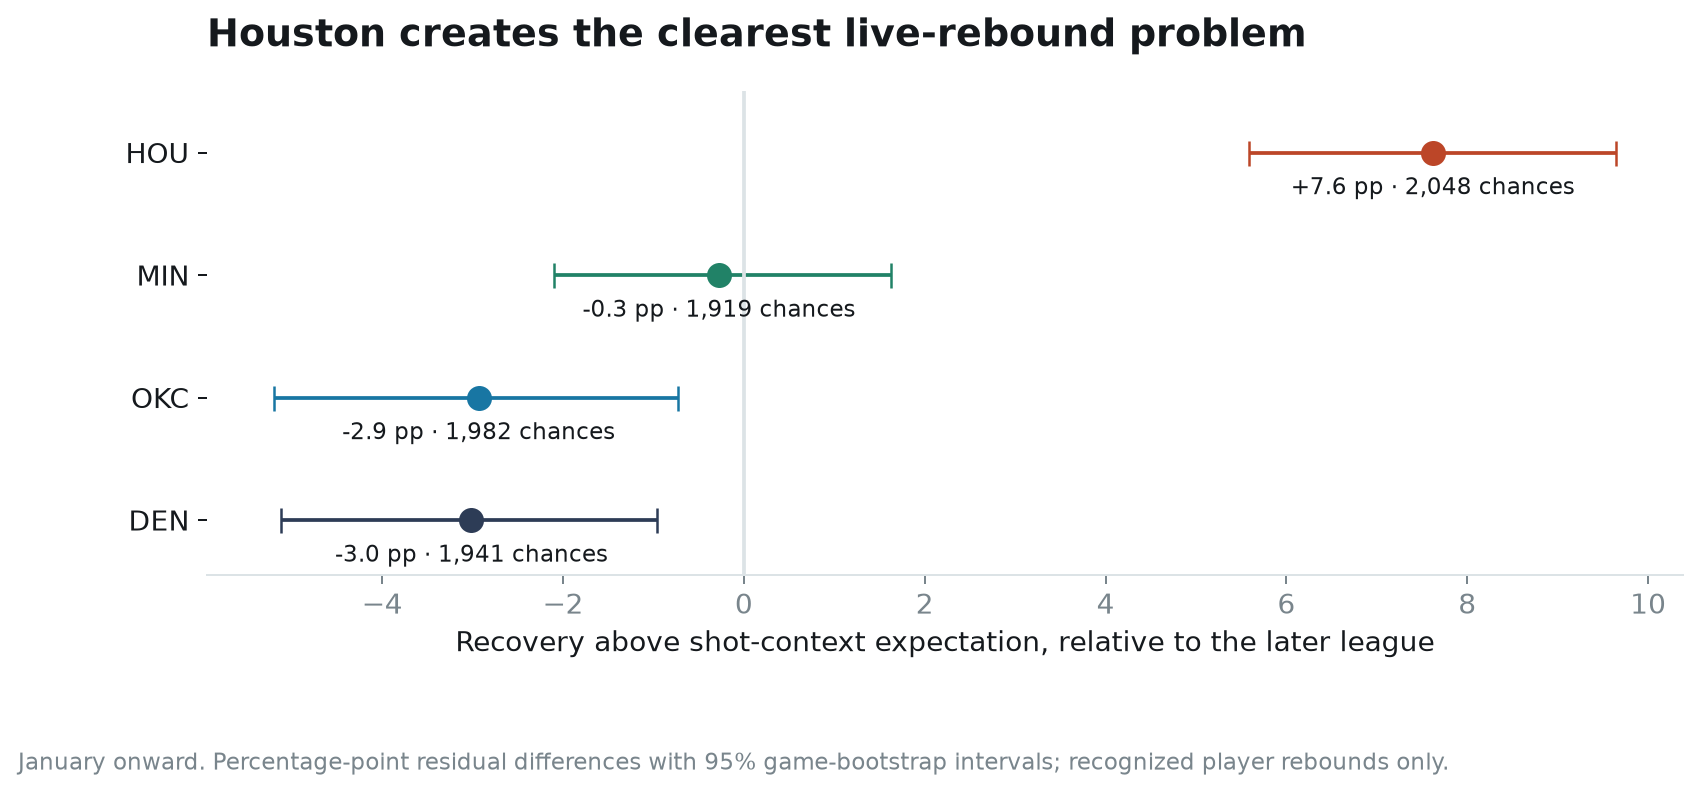

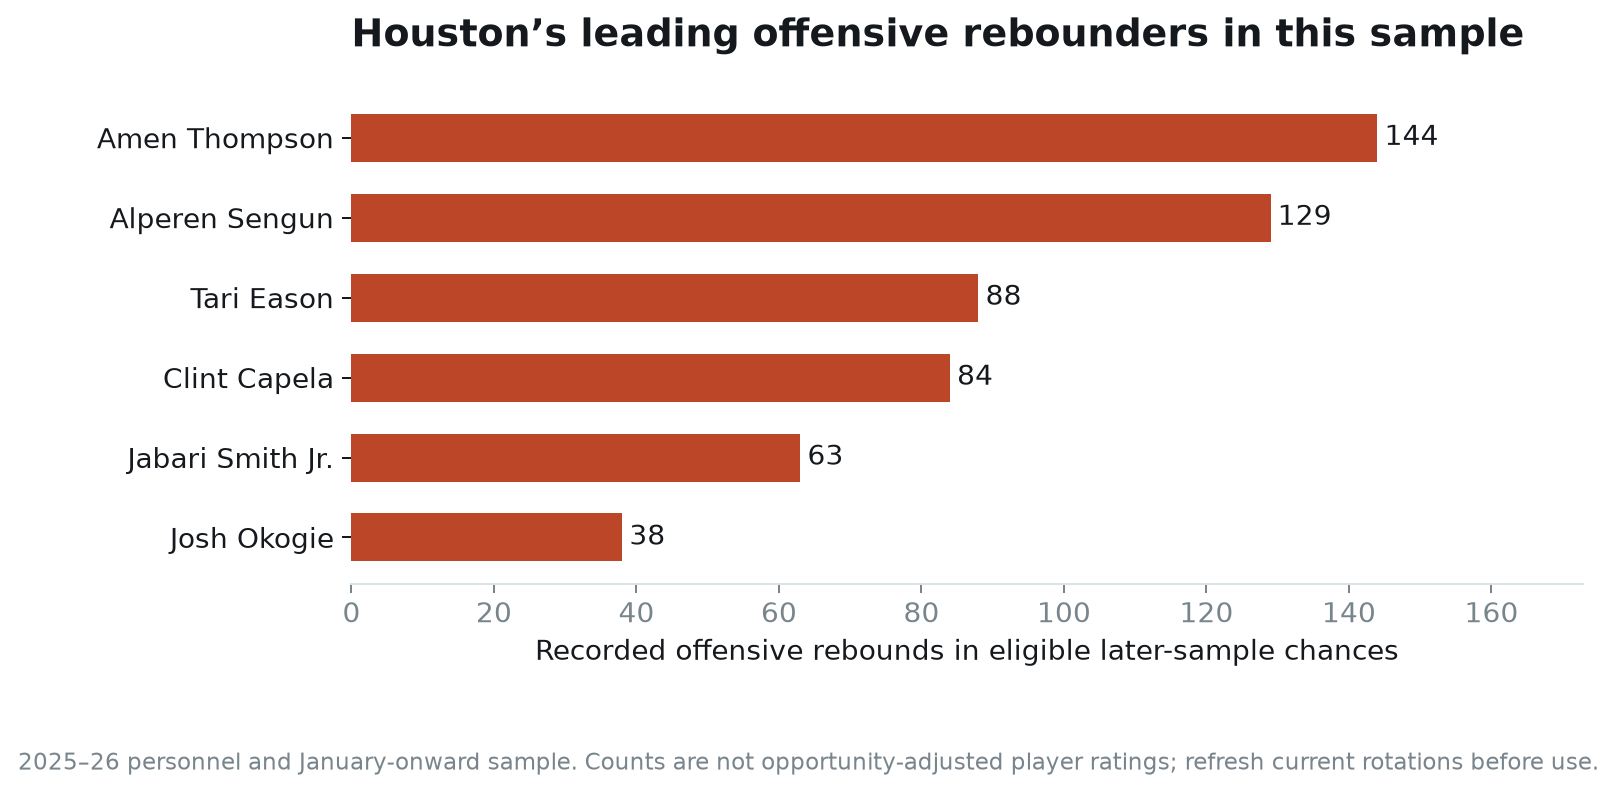

In [3]:
display(Image(filename='figures/glass_adjusted.png'))
display(Image(filename='figures/glass_rebounders.png'))

## Separate forecasting from the historical comparison
The prediction score uses the frozen early-sample model. The descriptive team residual is centered on later league calibration.

In [4]:
import json, numpy as np
d = pd.read_csv('data/glass_holdout.csv.gz')
p = pd.read_csv('results/glass_profiles.csv')
assert d.date.ge('2026-01-01').all()
for row in p.itertuples():
    assert np.isclose(row.league_relative_residual, d.loc[d.team.eq(row.team), 'residual'].mean() - d.residual.mean())
display(json.loads(Path('results/glass_validation.json').read_text()))
display(pd.read_csv('results/glass_spurs_review.csv').head(8))

{'train_chances': 40553,
 'test_chances': 59658,
 'model_logloss': 0.5740138654619885,
 'baseline_logloss': 0.5792641775569691,
 'model_brier': 0.19315820279206128,
 'baseline_brier': 0.1952502010644661,
 'loss_difference': -0.005250312094980687,
 'lower': -0.006177736917784028,
 'upper': -0.004379657094150895,
 'later_league_oreb_rate': 0.26594924402427167,
 'later_league_residual': -0.004229228099017014}

,game_id,event_id,rebound_event_id,date,team,opponent,player_id,player,rebounder_id,rebounder,...,distance,x,y,three,zone,probability,baseline,residual,loss_difference,zone_group
0,22500552,9,10,2026-01-11,MIN,SAS,1628978,Donte DiVincenzo,1628368,De'Aaron Fox,...,22.0,22.9,1.9,1,Right Corner 3,0.217287,0.271423,-0.217287,-0.071672,Missed three
1,22500552,18,19,2026-01-11,MIN,SAS,1630162,Anthony Edwards,1628368,De'Aaron Fox,...,22.0,-22.7,-1.6,1,Left Corner 3,0.211750,0.271423,-0.211750,-0.078722,Missed three
2,22500552,25,26,2026-01-11,MIN,SAS,1628978,Donte DiVincenzo,203497,Rudy Gobert,...,17.0,9.7,14.1,0,Mid-Range,0.207679,0.271423,0.792321,0.267682,Other missed two
3,22500552,27,28,2026-01-11,MIN,SAS,203497,Rudy Gobert,1641705,Victor Wembanyama,...,7.0,-2.9,6.9,0,In The Paint (Non-RA),0.232146,0.271423,-0.232146,-0.052505,Other missed two
4,22500552,35,36,2026-01-11,MIN,SAS,1630162,Anthony Edwards,1641705,Victor Wembanyama,...,18.0,17.4,5.5,0,Mid-Range,0.205107,0.271423,-0.205107,-0.087113,Other missed two
5,22500552,40,41,2026-01-11,MIN,SAS,203944,Julius Randle,1642264,Stephon Castle,...,12.0,0.6,12.1,0,In The Paint (Non-RA),0.237465,0.271423,-0.237465,-0.045554,Other missed two
6,22500552,53,54,2026-01-11,MIN,SAS,203944,Julius Randle,1642264,Stephon Castle,...,12.0,0.2,12.4,0,In The Paint (Non-RA),0.244783,0.271423,-0.244783,-0.035911,Other missed two
7,22500552,83,84,2026-01-11,MIN,SAS,1630183,Jaden McDaniels,1642844,Dylan Harper,...,23.0,-22.4,7.2,1,Left Corner 3,0.238047,0.271423,-0.238047,-0.044791,Missed three


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.